# 03 - Train and evaluate the IDRiD classifier

This notebook learns **two classes**: Normal (original grade 0) and DR (original grades 1-4). It does not predict the five separate grades. Run the EDA notebook first, then preprocessing, then this notebook.

The earlier report said 81.4% test accuracy, but the current saved baseline prediction file recalculates to 77.5% accuracy, 77.9% sensitivity, 76.5% specificity, and 0.877 AUC. These records disagree; see 04_IDRiD_Experiments.ipynb for a controlled reproduction and the record note.

## Cell 1 - Load libraries and locate the project

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, roc_auc_score

In [2]:
ROOT_OVERRIDE = None  # Set a folder path here only if automatic search fails.
if ROOT_OVERRIDE:
    ROOT = Path(ROOT_OVERRIDE).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    choices = [here, *here.parents, Path.home() / "Desktop" / "retinal-dr-classification"]
    ROOT = next((p for p in choices if (p / "data" / "IDRiD").is_dir()), None)
    if ROOT is None:
        raise FileNotFoundError("Set ROOT_OVERRIDE to the project folder.")
RUN_DIR = ROOT / "reports" / "IDRiD_clean_run"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 20261008
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(8)
print("Project:", ROOT)
print("Device:", DEVICE)

Project: C:\Users\PIXEL-PC\Desktop\retinal-dr-classification
Device: cpu


## Cell 2 - Load the prepared split lists

These files were created by the preprocessing notebook. Test images stay separate from training and validation.

In [3]:
train_data = pd.read_csv(RUN_DIR / "train_manifest.csv")
validation_data = pd.read_csv(RUN_DIR / "validation_manifest.csv")
test_data = pd.read_csv(RUN_DIR / "official_test_manifest.csv")
print("Training:", len(train_data), "Validation:", len(validation_data), "Test:", len(test_data))
display(pd.DataFrame({
    "train": train_data.label.value_counts().reindex([0, 1], fill_value=0),
    "validation": validation_data.label.value_counts().reindex([0, 1], fill_value=0),
    "test": test_data.label.value_counts().reindex([0, 1], fill_value=0),
}).rename(index={0: "Normal", 1: "DR"}))

Training: 329 Validation: 83 Test: 102


,train,validation,test
label,,,
Normal,106,27,34
DR,223,56,68


## Cell 3 - Repeat the model image transforms

Each original image is resized and cropped to 224 x 224. Random flipping happens only while training.

In [4]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(p=0.5), transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
evaluation_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(mean, std),
])

## Cell 4 - Make a small image loader

A dataset loader opens one photo, applies the correct transform, and returns its label.

In [5]:
class RetinalImages(Dataset):
    def __init__(self, table, transform):
        self.table = table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(ROOT / row.relative_path) as photo:
            photo = photo.convert("RGB")
        return self.transform(photo), int(row.label), row.image_id

## Cell 5 - Create batches

A batch is a small group of images processed together. Shuffling is used for training, not for evaluation.

In [6]:
BATCH_SIZE = 8
train_loader = DataLoader(RetinalImages(train_data, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
validation_loader = DataLoader(RetinalImages(validation_data, evaluation_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(RetinalImages(test_data, evaluation_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Training batches:", len(train_loader))

Training batches: 42


## Cell 6 - Check the imbalance and calculate weights

After excluding the unresolved pair and making the grouped split, training has 106 Normal and 223 DR images. Weighted loss gives more influence to the smaller Normal class. It does not change the labels or create new images.

In [7]:
training_counts = train_data.label.value_counts().reindex([0, 1], fill_value=0)
weights = len(train_data) / (2 * training_counts.to_numpy(dtype=np.float32))
weight_table = pd.DataFrame({"class": ["Normal", "DR"], "images": training_counts.values, "loss_weight": weights})
display(weight_table)
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
loss_function = nn.CrossEntropyLoss(weight=class_weights)

,class,images,loss_weight
0,Normal,106,1.551887
1,DR,223,0.737668


## Cell 7 - Set up the model

EfficientNet-B0 starts with general image features learned from ImageNet. Its last layer is changed to return two scores: Normal and DR.

In [8]:
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
model = model.to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
print("Model ready:", type(model).__name__)

Model ready: EfficientNet


## Cell 8 - Measure validation loss after an epoch

Validation loss helps us choose when the model performed best. It does not update model weights.

In [9]:
def validation_loss(model, loader):
    model.eval()
    total_loss = 0
    total_images = 0
    with torch.inference_mode():
        for photos, labels, _ in loader:
            photos = photos.to(DEVICE)
            labels = labels.to(DEVICE)
            scores = model(photos)
            total_loss += nn.functional.cross_entropy(scores, labels, reduction="sum").item()
            total_images += len(labels)
    return total_loss / total_images

## Cell 9 - Train the model

One epoch means the model has seen every training image once. We train for at most 8 epochs and save the version with the lowest validation loss. The official test images are not used here.

In [10]:
EPOCHS = 8
best_validation_loss = float("inf")
best_epoch = 0
history = []
MODEL_PATH = RUN_DIR / "best_model.pt"

for epoch in range(1, EPOCHS + 1):
    model.train()
    training_loss = 0
    for photos, labels, _ in train_loader:
        photos = photos.to(DEVICE)
        labels = labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        scores = model(photos)
        loss = loss_function(scores, labels)
        loss.backward()
        optimizer.step()
        training_loss += loss.item()

    training_loss = training_loss / len(train_loader)
    val_loss = validation_loss(model, validation_loader)
    history.append({"epoch": epoch, "training_loss": training_loss, "validation_loss": val_loss})
    print(f"Epoch {epoch}/{EPOCHS}: training loss {training_loss:.3f}; validation loss {val_loss:.3f}")

    if val_loss < best_validation_loss:
        best_validation_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), MODEL_PATH)

history = pd.DataFrame(history)
history.to_csv(RUN_DIR / "training_history.csv", index=False)
print("Best epoch:", best_epoch)

Epoch 1/8: training loss 0.554; validation loss 0.410
Epoch 2/8: training loss 0.374; validation loss 0.268
Epoch 3/8: training loss 0.343; validation loss 0.298
Epoch 4/8: training loss 0.266; validation loss 0.230
Epoch 5/8: training loss 0.182; validation loss 0.187
Epoch 6/8: training loss 0.152; validation loss 0.169
Epoch 7/8: training loss 0.155; validation loss 0.220
Epoch 8/8: training loss 0.082; validation loss 0.307
Best epoch: 6


## Cell 10 - Look at the learning curve

If training loss keeps going down but validation loss starts to rise, the model may be overfitting. We use the saved model from the lowest validation loss.

,epoch,training_loss,validation_loss
0,1,0.554019,0.409820
1,2,0.374253,0.267641
2,3,0.342692,0.298096
3,4,0.265790,0.230102
4,5,0.181833,0.186649
5,6,0.151715,0.169400
6,7,0.154905,0.219715
7,8,0.082352,0.306540


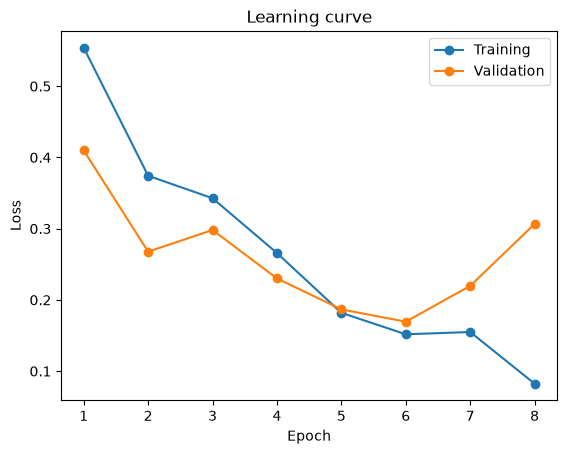

In [11]:
display(history)
plt.plot(history.epoch, history.training_loss, marker="o", label="Training")
plt.plot(history.epoch, history.validation_loss, marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning curve")
plt.legend()
plt.show()

## Cell 11 - Load the selected model and define simple predictions

In [12]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True))
model.eval()

def get_predictions(loader):
    labels_all, probabilities, ids = [], [], []
    with torch.inference_mode():
        for photos, labels, image_ids in loader:
            scores = model(photos.to(DEVICE))
            probabilities.extend(torch.softmax(scores, dim=1)[:, 1].cpu().numpy())
            labels_all.extend(labels.numpy())
            ids.extend(image_ids)
    labels_all = np.asarray(labels_all)
    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= 0.5).astype(int)
    return labels_all, predictions, probabilities, ids

## Cell 12 - Report performance clearly

Sensitivity tells us how many DR images were detected. Specificity tells us how many normal images were correctly recognized. The confusion counts make missed DR cases visible.

In [13]:
def report_scores(labels, predictions, probabilities):
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    return {
        "images": len(labels),
        "accuracy": accuracy_score(labels, predictions),
        "sensitivity": recall_score(labels, predictions, zero_division=0),
        "specificity": tn / (tn + fp),
        "roc_auc": roc_auc_score(labels, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

## Cell 13 - Check validation performance

In [14]:
y_val, pred_val, prob_val, val_ids = get_predictions(validation_loader)
validation_results = report_scores(y_val, pred_val, prob_val)
display(pd.Series(validation_results, name="Validation").to_frame())
pd.DataFrame({"image_id": val_ids, "true_label": y_val, "predicted_label": pred_val,
              "dr_probability": prob_val}).to_csv(RUN_DIR / "validation_predictions.csv", index=False)

,Validation
images,83.000000
accuracy,0.915663
sensitivity,0.892857
specificity,0.962963
roc_auc,0.984127
TN,26.000000
FP,1.000000
FN,6.000000
TP,50.000000


## Cell 14 - Final test evaluation

This is the final scoring step. The test set is used once, after selecting the model using validation. Do not tune the threshold on these test results and then report the same test as independent.

In [15]:
y_test, pred_test, prob_test, test_ids = get_predictions(test_loader)
test_results = report_scores(y_test, pred_test, prob_test)
display(pd.Series(test_results, name="Official test").to_frame())
print("DR images missed:", test_results["FN"])
print("Normal images incorrectly flagged:", test_results["FP"])
pd.DataFrame({"image_id": test_ids, "true_label": y_test, "predicted_label": pred_test,
              "dr_probability": prob_test}).to_csv(RUN_DIR / "official_test_predictions.csv", index=False)

,Official test
images,102.000000
accuracy,0.774510
sensitivity,0.779412
specificity,0.764706
roc_auc,0.877163
TN,26.000000
FP,8.000000
FN,15.000000
TP,53.000000


DR images missed: 15
Normal images incorrectly flagged: 8


## Cell 15 - Save a summary for later

In [16]:
summary = {
    "task": "two classes: grade 0 Normal; grades 1-4 DR",
    "training_images": len(train_data),
    "validation_images": len(validation_data),
    "test_images": len(test_data),
    "best_epoch": int(best_epoch),
    "test_results": {key: float(value) if isinstance(value, (np.floating, float)) else int(value)
                     for key, value in test_results.items()},
    "note": "Small single-source research baseline; not clinical-ready."
}
(RUN_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved results in:", RUN_DIR)

Saved results in: C:\Users\PIXEL-PC\Desktop\retinal-dr-classification\reports\IDRiD_clean_run


### What the model predicts

This model outputs one of two labels: **Normal** or **DR**. The original grade is used to create those labels, but the model does not output the severity grade. To predict grades 0, 1, 2, 3, and 4, a separate five-class training task and evaluation would be needed.

The prior report claimed 81.4% test accuracy, but current saved prediction artifacts recalculate to 77.5% accuracy, 77.9% sensitivity, 76.5% specificity, and 0.877 AUC (15 of 68 DR images missed). The README and prediction artifacts had conflicting numbers. See 04_IDRiD_Experiments.ipynb for the controlled comparison. This is a small research experiment, not a medical diagnostic tool.